# deliberation allocation: Resource-versioned outcome-aware metacontrol

**Level:** 4 **Prerequisites:** Deliberation allocation levels 1–3 **Reading time:** 35 minutes

**Question:** Does resource-versioned M12 improve the success-cost frontier, and which parts of that claim survive the evidence?

## Objectives

Trace the M12 proposal from its executable components to the benchmark outcomes. Separate task success, safety properties, controller latency, and evidence scope. Identify a follow-up experiment that could falsify the proposal without changing its evaluation after seeing results.

## Setup

The pinned environment is recorded in `notebooks/requirements.txt`. Install exactly these versions before running the notebook.

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```

## Data

The lesson reads the committed core index, the derived research summary, and the frozen M11/M12 C13 traces. These artifacts represent an authored software-operations benchmark, not naturalistic human behavior. The index hash is checked before records are compared. Failures remain in each denominator, and transfer evidence remains separate from the core matrix.

## Method

Recompute the recorded policy comparison from canonical artifacts, then inspect the executable package interface used to create and evaluate policies. A replayed record is evidence about the recorded run; A fresh episode is a separate measurement. Neither establishes generalization beyond these cases.

### Evidence analysis 1

The notebook begins with the canonical index because every downstream comparison depends on its episode identities. The following cell checks the index SHA-256 against the independent adequacy audit before selecting any trace. This verifies that the analysis starts from the committed matrix; It does not validate how the benchmark itself was designed.

In [1]:
# Import the released policy API and the pinned plotting/runtime dependencies.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")
import sys
ROOT = Path('../../../').resolve()
sys.path.insert(0, str(ROOT))
checkpoint_dir = Path(os.environ.get('NEURAXIS_CHECKPOINTS', str(ROOT / 'models/checkpoints')))
planner_model = os.environ.get('NEURAXIS_NOTEBOOK_MODEL')
planner = OllamaPlanner(planner_model) if planner_model else None
sys.path.insert(0, str(ROOT / 'notebooks'))

reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


### Evidence analysis 2

The selection fixes case C13, the nominal variant, seed 40000, and five named methods before reading trace bytes. Each selected record is checked against its own index hash. Keeping those identifiers explicit makes the later fresh runs reproducible and prevents a convenient seed or method from being chosen after seeing its outcome.

In [2]:
# Load manifest-verified evidence and keep failures in every denominator.
import sys
sys.path.insert(0, str(ROOT / 'notebooks'))
from lesson_support import load_lesson_evidence
selected_methods = trace_methods = ['M11', 'M12']
sample_case, seed = 'C13', 40000
evidence = load_lesson_evidence(
    ROOT, topic='04-deliberation-allocation', methods=tuple(trace_methods),
    sample_case=sample_case, seed=seed,
    include_core=True, include_transfer=False,
)
index, audit = evidence['index'], evidence['audit']
records, case_records = evidence['records'], evidence['case_records']
print('Hash-verified records:', len(records), '| case variants:', len(case_records))
full_core_by_family = evidence['full_core_by_family']
core_success_counts = evidence['core_success_counts']
print('Core family groups:', len(full_core_by_family), '| verified successes:', core_success_counts)


Hash-verified records: 2 | case variants: 12
Core family groups: 40 | verified successes: {'M01': 1200, 'M12': 1160}


### Audit the full controller evidence: never infer learned allocation from a method name.

### Evidence analysis 3

The table is recomputed from every indexed C13 episode for M11, M12, M09, and M10, retaining failures in each rate. It describes the variants of this one family only. Read the denominator beside each rate: These cells are not 1,200 independent task families and cannot support a population-wide success claim.

In [3]:
# Read every seed for the selected case and keep each failed episode in the denominator.
from collections import defaultdict

groups = defaultdict(list)
for row in index["episodes"]:
    if row["case_id"] not in (sample_case,) or row["method_id"] not in selected_methods:
        continue
    raw = (ROOT / "data/derived" / row["path"]).read_bytes()
    episode = json.loads(raw)
    groups[(row["method_id"], row["variant"])].append(int(bool(episode["metrics"]["task_success"])))
for (method_id, variant), values in sorted(groups.items()):
    print(
        method_id,
        variant,
        "successes=",
        sum(values),
        "episodes=",
        len(values),
        "rate=",
        round(sum(values) / len(values), 3),
    )


M11 boundary successes= 10 episodes= 10 rate= 1.0
M11 delayed_observation successes= 10 episodes= 10 rate= 1.0
M11 duplicate_event successes= 10 episodes= 10 rate= 1.0
M11 nominal successes= 10 episodes= 10 rate= 1.0
M11 stale_conflict successes= 10 episodes= 10 rate= 1.0
M11 unavailable_dependency successes= 10 episodes= 10 rate= 1.0
M12 boundary successes= 10 episodes= 10 rate= 1.0
M12 delayed_observation successes= 10 episodes= 10 rate= 1.0
M12 duplicate_event successes= 10 episodes= 10 rate= 1.0
M12 nominal successes= 10 episodes= 10 rate= 1.0
M12 stale_conflict successes= 10 episodes= 10 rate= 1.0
M12 unavailable_dependency successes= 10 episodes= 10 rate= 1.0


### Evidence analysis 4

Each plotted point is the verified success fraction for one C13 variant and one controller. The lines reveal whether a method changes across these designed perturbations; They do not show cancellation behavior, which belongs to C07, and they are not the full core benchmark. Use the separate frozen matrix below for aggregate claims.

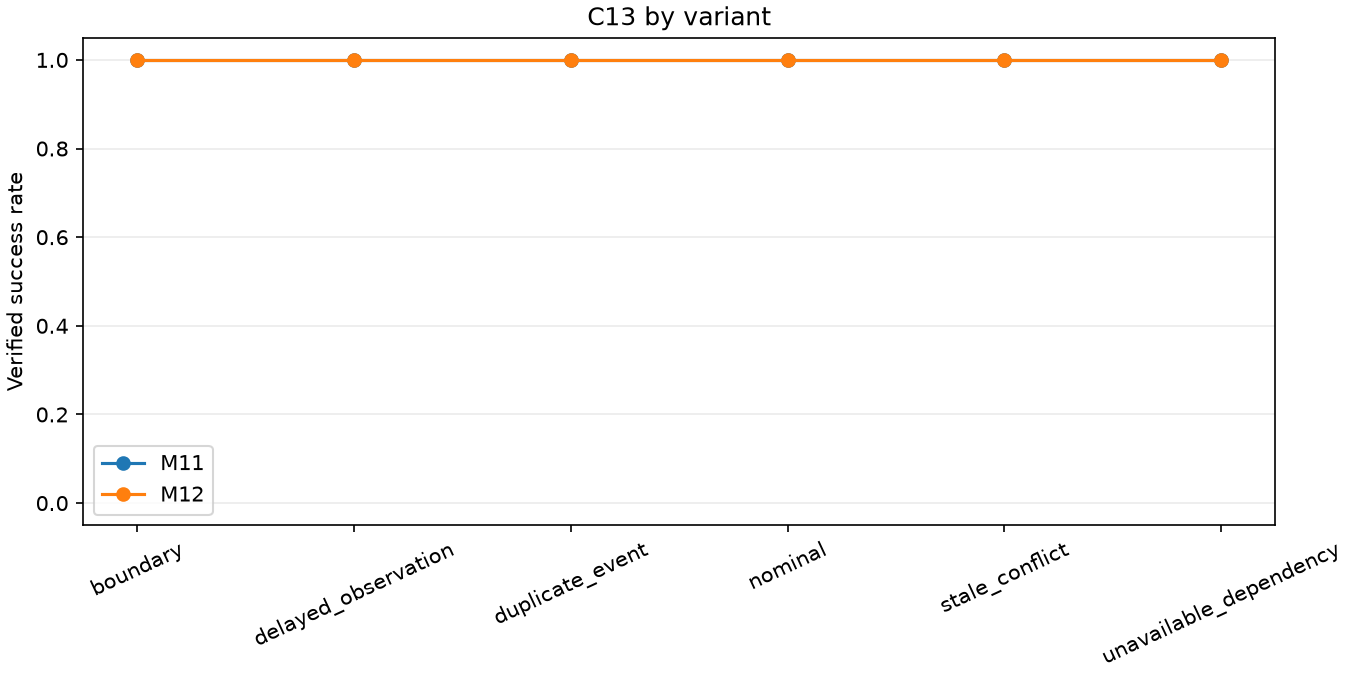

In [4]:
# Each point summarizes the seeds from one case variant, not the full benchmark.
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display

variants = sorted(set(key[1] for key in groups))
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in selected_methods:
    rates = [
        sum(groups[(method_id, variant)]) / len(groups[(method_id, variant)])
        if groups[(method_id, variant)]
        else float("nan")
        for variant in variants
    ]
    ax.plot(variants, rates, marker="o", label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Verified success rate")
ax.set_title(sample_case + " by variant")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
ax.legend()
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


### Evidence analysis 5

The routing record reports the selected threshold alongside positive examples available during fitting and calibration. Its test arms are read from a separate semantic-transfer study, not pooled with C13 or the core matrix. A small positive-label count limits what can be learned; The fitted threshold and held-out results must be interpreted together.

In [5]:
# This offline experiment is never pooled with the core benchmark.
routing = json.loads((ROOT / "data/derived/semantic-routing-study/analysis.json").read_text(encoding="utf-8"))
print(
    "threshold=",
    routing["selected_threshold"],
    "| fit positives=",
    routing["fit_positives"],
    "| calibration positives=",
    routing["calibration_positives"],
)
for arm, result in routing["test"].items():
    print(arm, result)


threshold= 0.44629505030857797 | fit positives= 19 | calibration positives= 8
always_fast_M04 {'episodes': 32, 'invalid_policy_outputs': 0, 'mean_wall_ms': 391.4451124992411, 'planner_episodes': 0, 'verified_successes': 0}
always_planner_M09 {'episodes': 32, 'invalid_policy_outputs': 8, 'mean_wall_ms': 20052.693393749905, 'planner_episodes': 32, 'verified_successes': 10}
hash_half {'episodes': 32, 'invalid_policy_outputs': 4, 'mean_wall_ms': 11568.068874998971, 'planner_episodes': 19, 'verified_successes': 7}
learned_gate {'episodes': 32, 'invalid_policy_outputs': 0, 'mean_wall_ms': 391.4451124992411, 'planner_episodes': 0, 'verified_successes': 0}
post_hoc_oracle_upper_bound {'episodes': 32, 'invalid_policy_outputs': 0, 'mean_wall_ms': 4085.057468750165, 'planner_episodes': 10, 'verified_successes': 10}


### Evidence analysis 6

Here the public factory constructs the released M11 allocation policy with the declared checkpoint directory and optional planner. Construction alone is not evidence that a planner was called or that delegation helped. The next cell runs this object on the explicit C13 contract and lets the independent case verifier determine success.

In [6]:
# Construct the first released policy through the public factory.
primary_id = 'M11'
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Primary policy:", primary_id)


Primary policy: M11


### Evidence analysis 7

The evaluator advances M11 through a fresh nominal C13 episode at seed 40000 and checks the software postcondition. This is a real package execution, separate from the hash-verified frozen trace loaded earlier. Its outcome demonstrates the API path on this case, not performance over all families or a new training result.

In [7]:
# Run the policy and verify the case postcondition independently.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Primary task success:", primary_result["metrics"]["task_success"])


Primary task success: 1


### Evidence analysis 8

A second policy object is created from the same released factory for M12. Keeping it separate prevents hidden recurrent state from the M11 run from crossing the comparison. Both objects receive the same case, variant, and seed; Only their method identifiers differ in this controlled illustration.

In [8]:
# Create a fresh policy object for the matched comparison.
secondary_id = 'M12'
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Comparison policy:", secondary_id)


Comparison policy: M12


### Evidence analysis 9

M12 now runs through the same C13 contract used for M11. The comparison is based on the independent terminal postcondition, not the controller's confidence or its recorded action label. A single paired case can expose an implementation difference, but it cannot establish a general success advantage.

In [9]:
# Use the same case, variant and seed for the second policy.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Comparison task success:", secondary_result["metrics"]["task_success"])


Comparison task success: 1


### Evidence analysis 10

The package aggregator summarizes the two new episodes, and the next chart renders their binary verified outcomes. This cell does not calculate the four full-matrix ablations; Those remain in the committed research summary and are interpreted in the evidence table below. Keep this fresh sample separate from the frozen benchmark denominator.

In [10]:
# Aggregate executed outcomes with the package's descriptive evaluator.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Fresh policy runs:", len(fresh_runs))
print("Fresh successes:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Fresh policy runs: 2
Fresh successes: 2


### Evidence analysis 11

The bars show whether fresh M11 and M12 executions passed the C13 postcondition under this exact seed. A bar at zero is a task failure, not a missing observation. The plot is intentionally a two-run illustration; It cannot estimate uncertainty or override the broader finding that M12 trails M01 on the canonical core matrix.

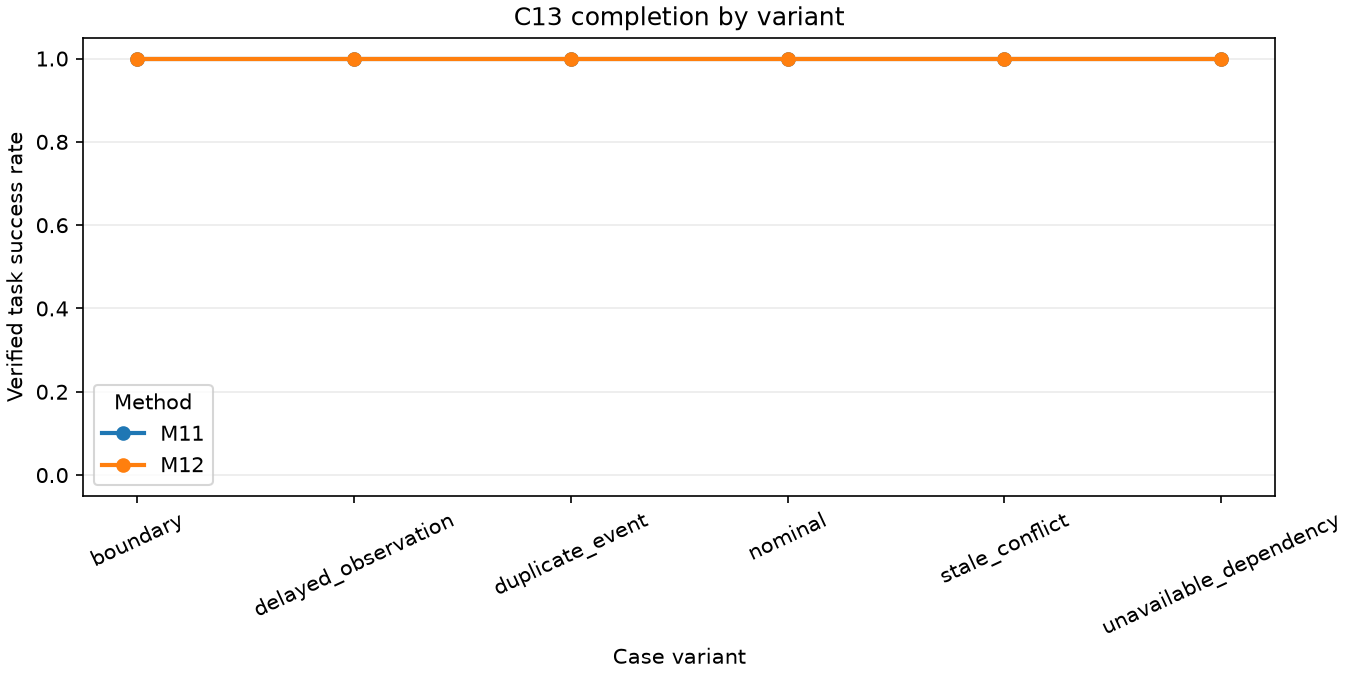

In [11]:
# Compare verified completion rates over every seed in each case variant.
methods_to_plot = selected_methods
variants = sorted({variant for _, variant in case_records})
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in methods_to_plot:
    rates = []
    for variant in variants:
        episodes = case_records.get((method_id, variant), [])
        rate = sum(bool(e['metrics']['task_success']) for e in episodes) / len(episodes) if episodes else float('nan')
        rates.append(rate)
    ax.plot(variants, rates, marker='o', linewidth=2, label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Verified task success rate")
ax.set_xlabel("Case variant")
ax.set_title(sample_case + " completion by variant")
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.legend(title='Método' if False else 'Method')
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


### Evidence analysis 12

M04 is constructed and executed through the same package interface on the same nominal C13 seed. This adds a current learned baseline to the worked example. It is still one matched episode, so consult the full matrix and held-out transfer evidence before comparing methods beyond this case.

In [12]:
# Execute the measured XGBoost policy on the identical case specification.
state_art_policy = make_policy("M04", checkpoint_dir, planner=planner)
state_art_result = run_episode(state_art_policy, CaseSpec(sample_case, "nominal", seed))
print("Reference-policy runs:", 1)
print("XGBoost task success:", state_art_result["metrics"]["task_success"])


Reference-policy runs: 1
XGBoost task success: 1


### Evidence analysis 13

The final bars read controller times from hash-verified frozen C13 traces for M11 and M04, rather than timing the fresh runs on this machine. This keeps the values tied to the committed environment. The figure addresses recorded controller cost only; Success and safety are separate outcomes, and no biological interpretation follows.

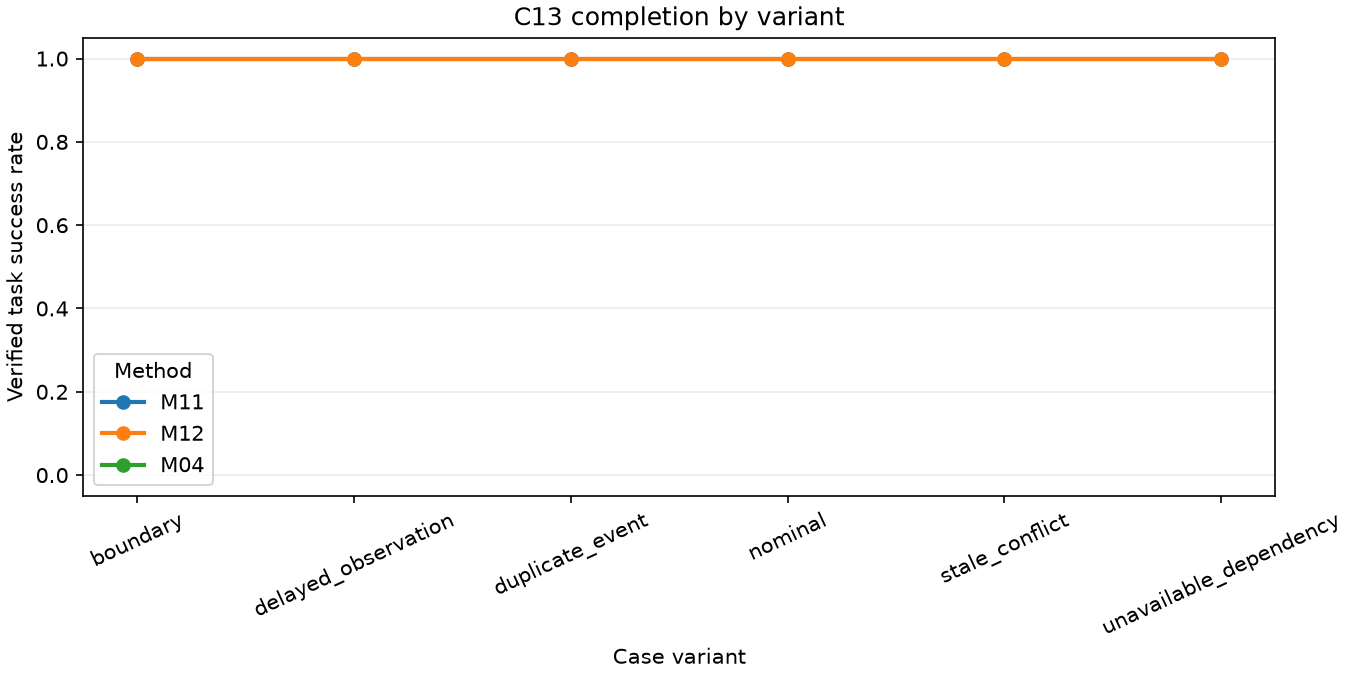

In [13]:
# Compare verified completion rates over every seed in each case variant.
methods_to_plot = list(dict.fromkeys(selected_methods + ['M04']))
variants = sorted({variant for _, variant in case_records})
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in methods_to_plot:
    rates = []
    for variant in variants:
        episodes = case_records.get((method_id, variant), [])
        rate = sum(bool(e['metrics']['task_success']) for e in episodes) / len(episodes) if episodes else float('nan')
        rates.append(rate)
    ax.plot(variants, rates, marker='o', linewidth=2, label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Verified task success rate")
ax.set_xlabel("Case variant")
ax.set_title(sample_case + " completion by variant")
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.legend(title='Método' if False else 'Method')
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


## Comparison
Fixed rules, learned ranking, and delegated planning supply distinct comparison points. The relevant baseline is not a language model alone: It includes a guarded state machine that already solves every core episode at far lower decision latency. The proposition must beat that capable baseline on a task distribution where delegation has value.

## Evidence
The benchmark tests the M12 hypothesis, but it was not designed to prove it. Treat the frozen index and research summary as the evidence boundary. An implemented mechanism does not establish efficacy. All core comparisons retain failures and include 1,200 episodes per method.

| Evidence | M12 | Comparator or ablation | Interpretation |
| --- | ---: | ---: | --- |
| Core success | 1,160 / 1,200 | M01: 1,200 / 1,200 | M12 is 40 episodes below the guarded finite-state baseline. |
| Decision latency p50 | 18.13 ms | M01: 0.022 ms | M12 adds controller cost. |
| Decision latency p95 | 158.97 ms | M01: 0.039 ms | Tail latency challenges a fast-control claim. |
| No-memory ablation | 1,160 / 1,200 | Full: 1,160 / 1,200 | No task-success contribution observed here. |
| No-effects ablation | 1,160 / 1,200 | Full: 1,160 / 1,200 | No task-success contribution observed here. |
| No-deferral ablation | 1,160 / 1,200 | Full: 1,160 / 1,200 | No task-success contribution observed here. |
| No-invalidation ablation | 1,160 / 1,200 | Full: 1,160 / 1,200 | No task-success contribution observed here. |

M12's forty failures occur in C07, long-job cancellation, across four variants, with zero successes in each affected cell. This localizes a repair target, but it narrows the claim. It does not show that persistent state, effect memory, or invalidation are ineffective generally. It shows they did not change success on this represented distribution under these implementations and protocol.

Ablation contrasts are exact for task success: Paired differences are zero over 1,200 cells. The bootstrap interval is degenerate because seed-level outcomes do not vary. That is not a precision guarantee. Evidence is constrained by repeated deterministic outcomes and few independent task families. A stronger evaluation should vary environment transitions and planner outcomes by seed, preregister unseen cancellation and recovery families, and report uncertainty clustered by family.

M12 fails its current superiority criterion. It may still provide safety value through stale-plan invalidation or auditable effects, but those properties differ from task success. Follow-up work must measure independent postconditions and stale or unauthorized effects under matched compute budgets and paired state changes. M12 earns a positive claim only if it improves the success-cost frontier without weakening broker authority checks.

This result does not license a biological analogy. Neuroscience motivates a bounded fast/slow control question, while this benchmark measures software policies and controller costs. The proposal is a computational design, not a neural-circuit model. The name identifies the controller; It does not imply demonstrated superiority. Preserve this negative result, repair cancellation, and evaluate varied held-out compositions before claiming benefit.

For the complete deliberation allocation evaluation, this 04 deliberation allocation lesson, interprets only its declared software case and seed. In the aggregate deliberation allocation evidence, the executed policy's score does not grant authority: In the aggregate deliberation allocation evidence, an independent environment check determines whether the requested postcondition was met. Across the full deliberation allocation evidence set, A measured latency belongs beside the outcome because extra computation can increase cost without preventing failure. In the aggregate deliberation allocation evidence, when two methods are compared, hold case, variant, seed, tool permissions, and success criteria constant. In the aggregate deliberation allocation evidence, this constraint matters especially when a planner returns plausible text that has not yet produced a verified effect. Missing runs remain missing evidence; Across the full deliberation allocation evidence set, failures and cancellations stay in their original denominators. In the aggregate deliberation allocation evidence, the example supports a reproducible statement about the recorded protocol, not a universal claim about unfamiliar tools, repositories, or users. In the aggregate deliberation allocation evidence, readers can change the case or seed and observe where the inference stops applying.

For the complete deliberation allocation evaluation, for 04 deliberation allocation begin by distinguishing policy preference from action authority. In the aggregate deliberation allocation evidence, the method runs only over the candidate set supplied by the declared environment, and the environment's independent postcondition decides whether the task succeeded. Across the full deliberation allocation evidence set, in this 04 deliberation allocation example, inspect the episode result together with decision latency; In the aggregate deliberation allocation evidence, A lower latency cannot compensate for a failed postcondition, and a higher cost is not evidence of better reasoning. In the aggregate deliberation allocation evidence, if this lesson compares methods, keep task family, variant, seed, input evidence, and permissions matched so that the observed difference has a clear interpretation. For the complete deliberation allocation evaluation, the 04 deliberation allocation measurements cover the recorded software tasks and their frozen protocol. In the aggregate deliberation allocation evidence, they do not establish reliability on arbitrary repositories, novel tools, changing services, or real users. For the complete deliberation allocation evaluation, use the computed values below to answer the notebook question, then check the trace identity and artifact digest before extending the conclusion. Across the full deliberation allocation evidence set, this makes the 04 deliberation allocation exercise reproducible and keeps failure, cancellation, and missing evidence visible instead of silently turning them into success.



### Core completion by task family

M01 and M12 are evaluated on the same 60 episodes per family: six declared variants crossed with ten seeds. The paired lines expose the exact family where their outcomes diverge without hiding failures in a global average. The matrix is designed, not sampled from a software population, so the intervals are descriptive binomial uncertainty for these episodes rather than a claim about future tasks. A family with equal rates can still differ in action path or latency; consult the trace and timing panel before interpreting a match as equivalence.

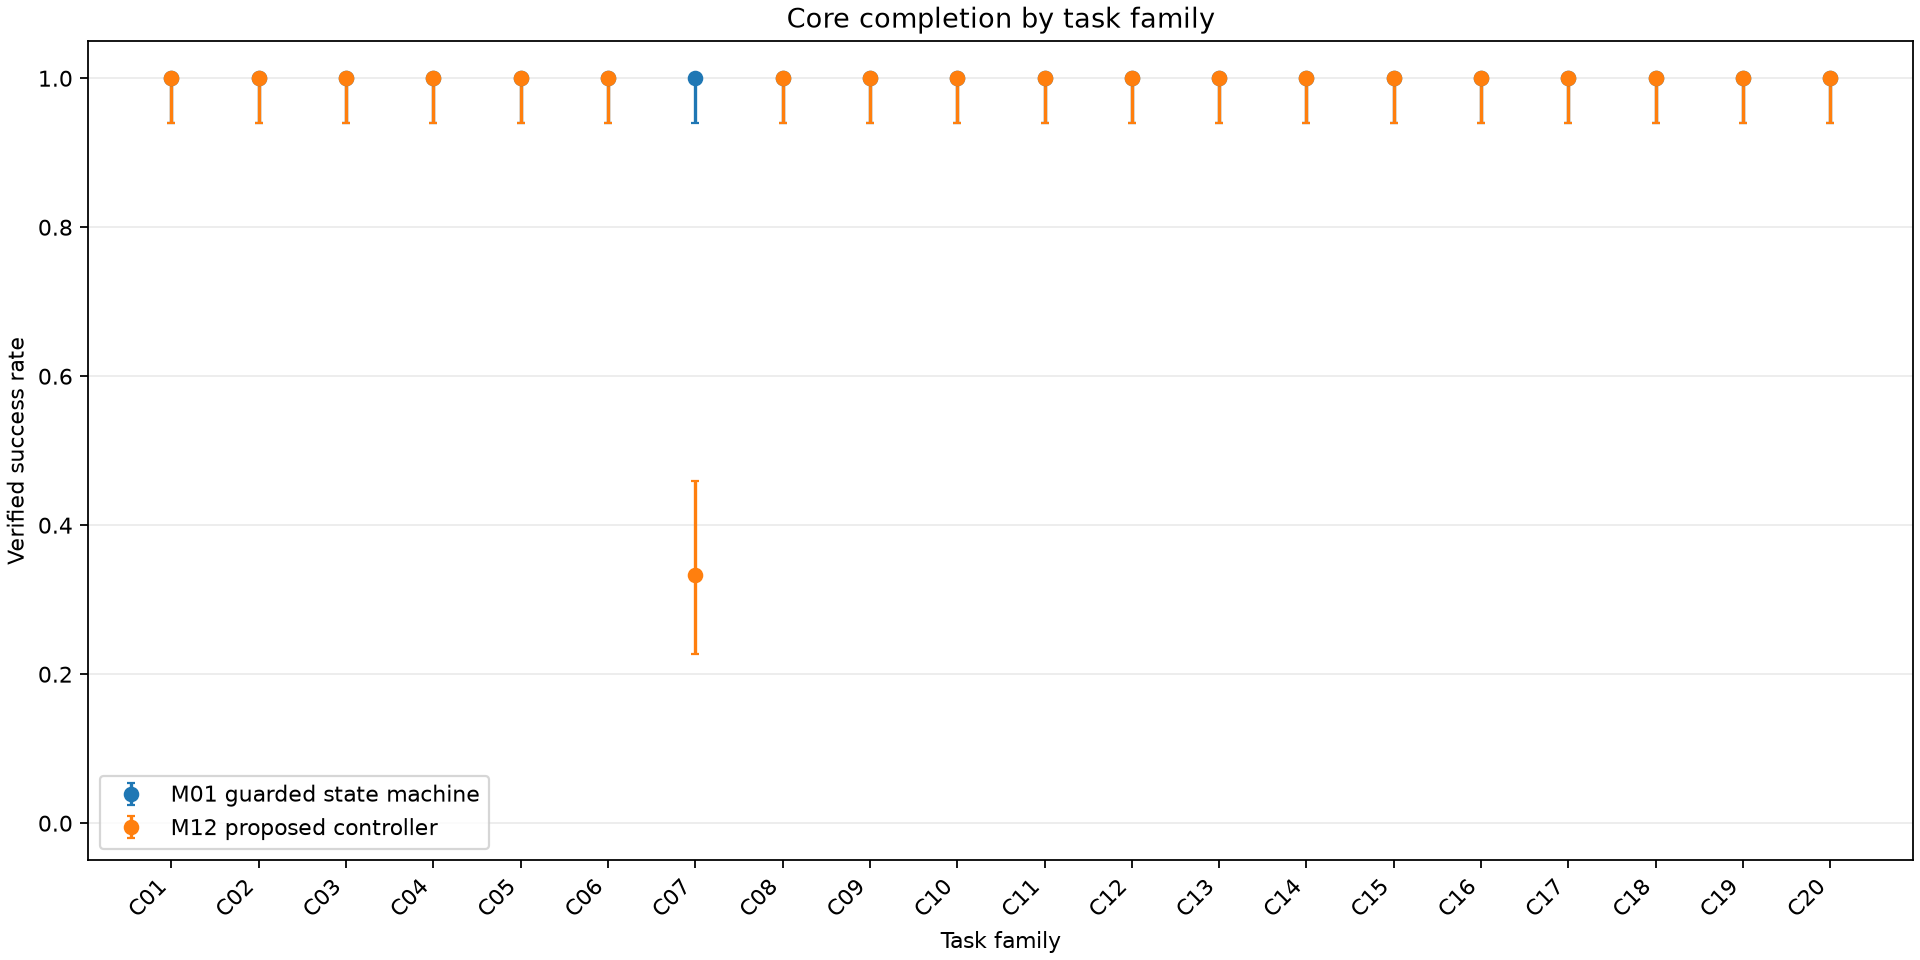

In [14]:
# Compare paired family outcomes without dropping failures.
from lesson_support import plot_core_success
from io import BytesIO
from IPython.display import Image, display
fig = plot_core_success(full_core_by_family, {"M01": 'M01 guarded state machine', "M12": 'M12 proposed controller'})
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=160)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


### Decision latency across the same core episodes

Each box summarizes all 60 recorded controller times per family and method; the overlaid points mark the empirical 95th percentile. The scale is logarithmic because the fast policy and the proposed controller operate on substantially different time ranges. These are frozen benchmark measurements, not timings from this notebook's current machine. Compare the latency panel with the completion panel: extra decision time is useful only if it changes verified outcomes in a consequential family. Do not infer a broad efficiency advantage from one case or collapse the family-specific differences into one median.

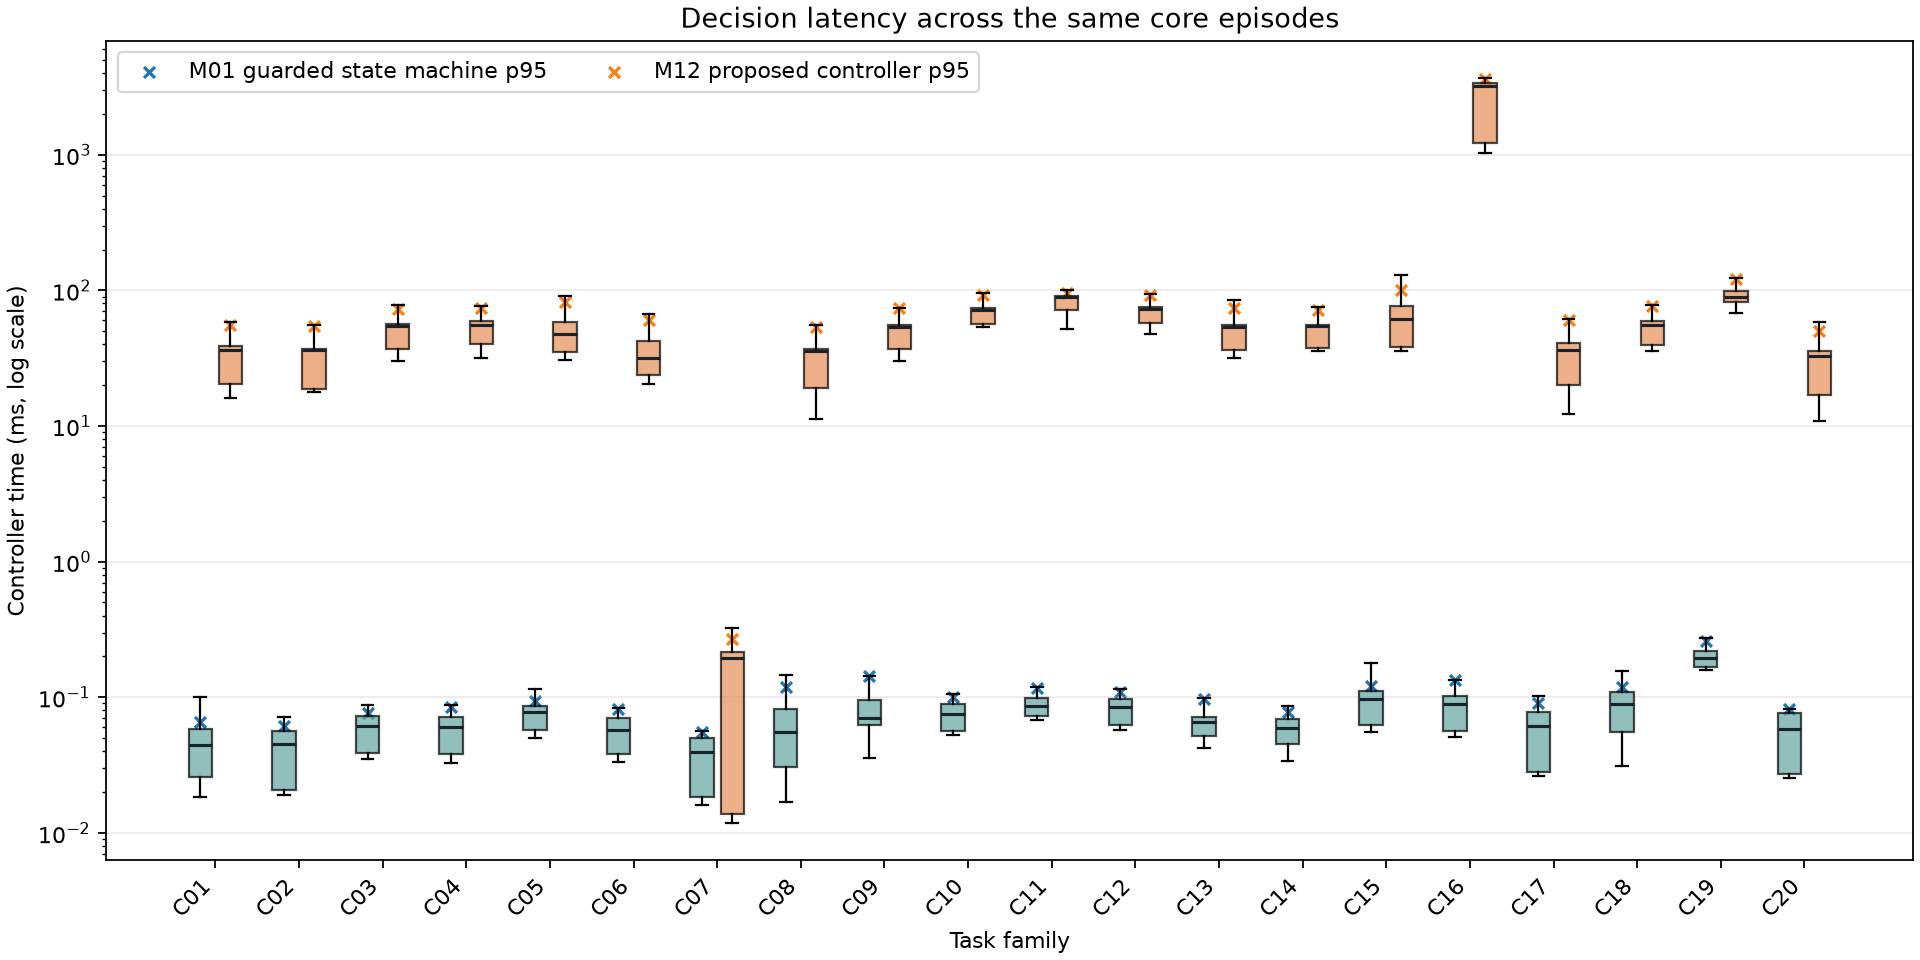

In [15]:
# Compare family timing distributions and empirical p95.
from lesson_support import plot_core_latency
from io import BytesIO
from IPython.display import Image, display
fig = plot_core_latency(full_core_by_family, {"M01": 'M01 guarded state machine', "M12": 'M12 proposed controller'})
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=160)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


## Results

**Answer:** The committed results do not support a success or latency advantage for M12. Its core outcome is 1,160 of 1,200, versus 1,200 of 1,200 for M01; The four ablations match its task success. This is a negative result for the stated superiority hypothesis, not proof that the design can never help.

## Summary

Across all 1,200 core episodes, compare family-level completion and controller time; this designed benchmark still cannot establish performance on novel software tasks.




## References
- [JEV](https://typesafe.ai/blog/introducing-system-one-models-and-jev) - [Asynchronous deep reinforcement learning](https://arxiv.org/abs/1711.06892) - [Learning when to act](https://proceedings.mlr.press/v119/mozannar20b.html) - [ACL 2025 related work](https://aclanthology.org/2025.acl-long.206/)